In [265]:
import numpy as np
rng = np.random.default_rng()

import seaborn as sns
import matplotlib.pyplot as plt

In [266]:
#risk_probabilities = np.array([1.0,0.0,0.0])  # the probability of being no risk, risky, risky + recent infection
risk_probabilities = np.array([0.6,0.3,0.1])
risk_ratios = np.array([1,1.5,2])
risk_names = ["regular", "intermediate", "high"]
true_strain_probs = np.array([0.5,0.35,0.15])
uti_prev = 0.15

# generate patients
num_patients = 100000
patients = []
uti_count = 0
strain_counts = np.array([0,0,0])

for i in range(0,num_patients):
    risk_fac = risk_ratios[rng.choice(3, p=risk_probabilities)]
    uti_prob = min(risk_fac*uti_prev, 1)
    uti_status=(rng.binomial(1,uti_prob)==1)
    patient_status = {"uti_status": uti_status, "uti_strain": None, "risk_factor": risk_fac}
    if uti_status:
        patient_status["uti_strain"] = rng.choice(3, p=true_strain_probs)
        uti_count += 1
        strain_counts[patient_status["uti_strain"]] += 1

    patients.append(patient_status)

print(f"True UTI prevalence: {uti_prev}")
print(f"Measured UTI prevalence: {uti_count/num_patients}\n")

print(f"True strain breakdown: {true_strain_probs}")
print(f"Strain breakdown: {strain_counts/uti_count}")

True UTI prevalence: 0.15
Measured UTI prevalence: 0.18591

True strain breakdown: [0.5  0.35 0.15]
Strain breakdown: [0.49905868 0.34704965 0.15389167]


In [267]:
# define the capabilities of the diagnostics
phys_uti_prev = rng.beta(3,7)  # total uti prevalence
phys_strain_probs = rng.dirichlet([60,30,10])  # first line susceptible, second line susceptible, total resistance
diag_sens_spec = {"dipstick": [0.7,0.05], "urine_culture": [0.9,0.03], "rapid_test": [0.95,0.01], "rapid_plus_ast": [0.95,0.0]}
all_strategies = ["clinical", "dipstick", "urine_culture", "rapid_test", "rapid_plus_ast"]

# valid choices are clinical, dipstick, urine_culture, rapid_test, rapid_plus_ast
def diagnostic_output(patient_status, strategy="clinical"):
    # by default, there is no strain chosen
    strain_diagnosis = None

    # evaluate patient using chosen strategy
    if strategy == "clinical":
        uti_diagnosis = (1==rng.binomial(1, patient_status["risk_factor"]*phys_uti_prev))
        if uti_diagnosis:
            strain_diagnosis = rng.choice(3, p=phys_strain_probs)
    
    elif strategy in ["dipstick", "urine_culture", "rapid_test"]:
        if patient_status["uti_status"]:
            true_pos_prob = diag_sens_spec[strategy][0]
            uti_diagnosis = (1==rng.binomial(1, true_pos_prob))
        else:
            false_pos_prob = diag_sens_spec[strategy][1]
            uti_diagnosis = (1==rng.binomial(1, false_pos_prob))
        
        if uti_diagnosis:
            strain_diagnosis = rng.choice(3, p=phys_strain_probs)
    
    elif strategy == "rapid_plus_ast":
        if patient_status["uti_status"]:
            true_pos_prob = diag_sens_spec["rapid_plus_ast"][0]
            uti_diagnosis = (1==rng.binomial(1, true_pos_prob))
        else:
            false_pos_prob = diag_sens_spec["rapid_plus_ast"][1]
            uti_diagnosis = (1==rng.binomial(1, false_pos_prob))
        
        if uti_diagnosis:
            strain_diagnosis = patient_status["uti_strain"]  # what happens if this is a false positive??
    
    else:
        raise ValueError(f"Invalid diagnostic strategy: {strategy}")
    
    return uti_diagnosis, strain_diagnosis

In [268]:
conf_mat_dict = {}
for chosen_strategy in all_strategies:
    # to analyze the success rates of the strategies, we compute confusion matrices for both strain diagnosis
    # and whether the uti was detected in the first place, for each risk group
    strain_confusion_matrices = [np.zeros((len(true_strain_probs),len(true_strain_probs))) for _ in range(0,3)]
    uti_confusion_matrices = [np.zeros((2,2)) for _ in range(0,3)]
    overall_confusion_matrices = [np.zeros((1+len(true_strain_probs),1+len(true_strain_probs))) for _ in range(0,3)]

    for patient_status in patients:
        true_uti_status, true_strain, risk_factor = patient_status["uti_status"], patient_status["uti_strain"], patient_status["risk_factor"]
        patient_risk_status = int(np.flatnonzero(risk_ratios == risk_factor)[0])
        phys_uti_diag, phys_uti_strain = diagnostic_output(patient_status, strategy=chosen_strategy)

        if phys_uti_diag:
            total_phys_index = phys_uti_strain + 1
        else:
            total_phys_index = 0
        
        if true_uti_status:
            total_true_index = true_strain + 1
        else:
            total_true_index = 0
        overall_confusion_matrices[patient_risk_status][total_true_index, total_phys_index] += 1 

        # if physician has correctly determined there is a uti, check if they get the strain right
        if true_uti_status and phys_uti_diag:
            strain_confusion_matrices[patient_risk_status][true_strain, phys_uti_strain] += 1 

        true_uti_status = int(true_uti_status)
        phys_uti_status = int(phys_uti_diag)
        uti_confusion_matrices[patient_risk_status][true_uti_status, phys_uti_status] +=1

    for i in range(0,3):
        uti_confusion_matrices[i] = uti_confusion_matrices[i]/uti_confusion_matrices[i].sum()
        strain_confusion_matrices[i] = strain_confusion_matrices[i]/strain_confusion_matrices[i].sum()
        overall_confusion_matrices[i] = overall_confusion_matrices[i]/overall_confusion_matrices[i].sum()

    
    conf_mat_dict[chosen_strategy] = {"uti": uti_confusion_matrices, "strain": strain_confusion_matrices, "overall": overall_confusion_matrices}


In [287]:
chosen_strategy = "rapid_plus_ast"
uti_confusion_matrices = conf_mat_dict[chosen_strategy]["uti"]
strain_confusion_matrices = conf_mat_dict[chosen_strategy]["strain"]
overall_confusion_matrices = conf_mat_dict[chosen_strategy]["overall"]

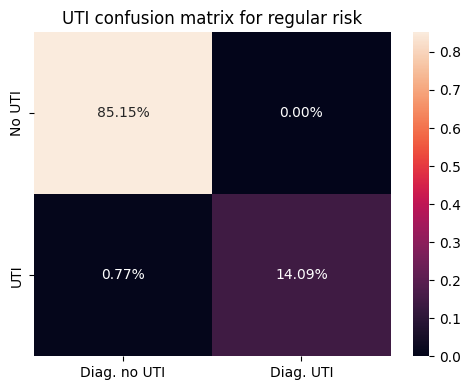

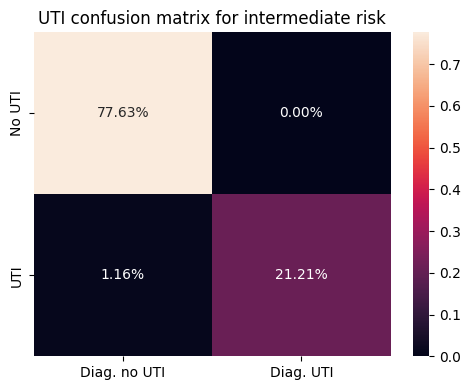

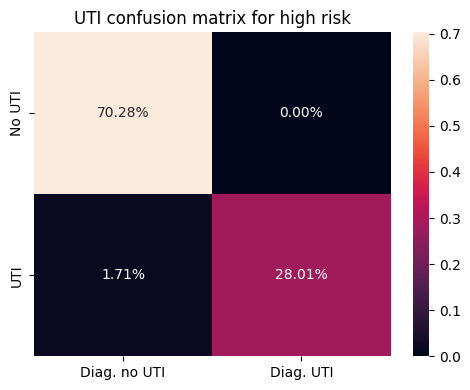

In [288]:

for i, matrix in enumerate(uti_confusion_matrices):
    normalized = matrix / matrix.sum()

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        normalized,
        yticklabels=["No UTI", "UTI"],
        xticklabels=["Diag. no UTI", "Diag. UTI"],
        annot=True,
        fmt=".2%",
    )
    plt.title(f"UTI confusion matrix for {risk_names[i]} risk")
    plt.tight_layout()
    plt.show()

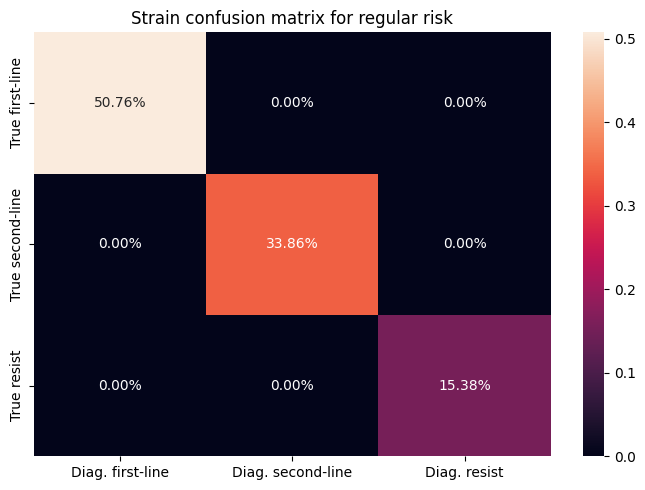

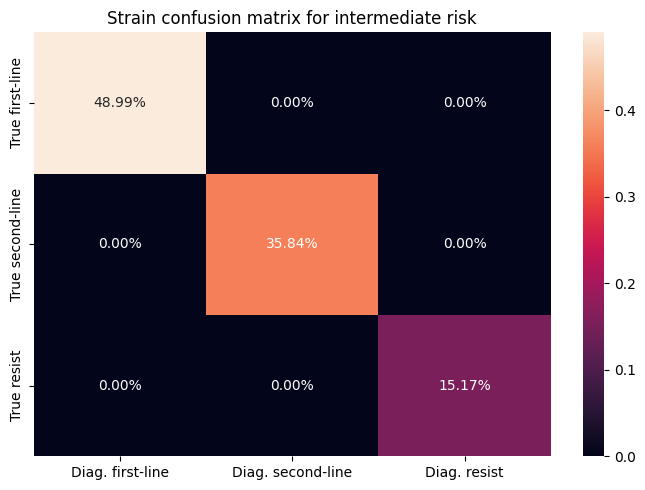

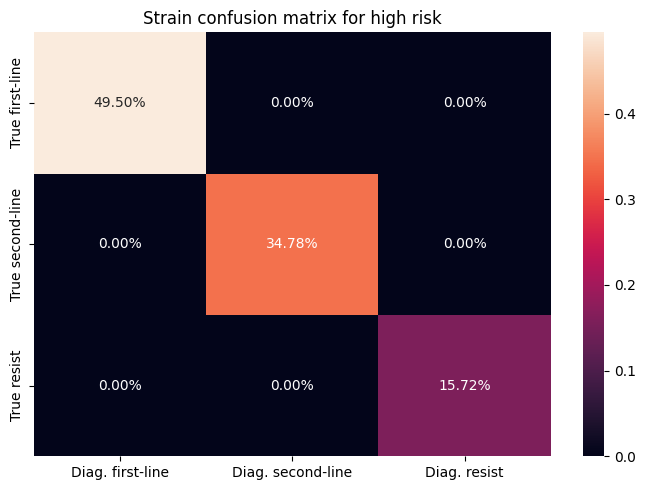

In [289]:
for i, matrix in enumerate(strain_confusion_matrices):
    normalized = matrix / matrix.sum()

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        normalized,
        yticklabels=["True first-line", "True second-line", "True resist"],
        xticklabels=["Diag. first-line", "Diag. second-line", "Diag. resist"],
        annot=True,
        fmt=".2%",
    )
    plt.title(f"Strain confusion matrix for {risk_names[i]} risk")
    plt.tight_layout()
    plt.show()

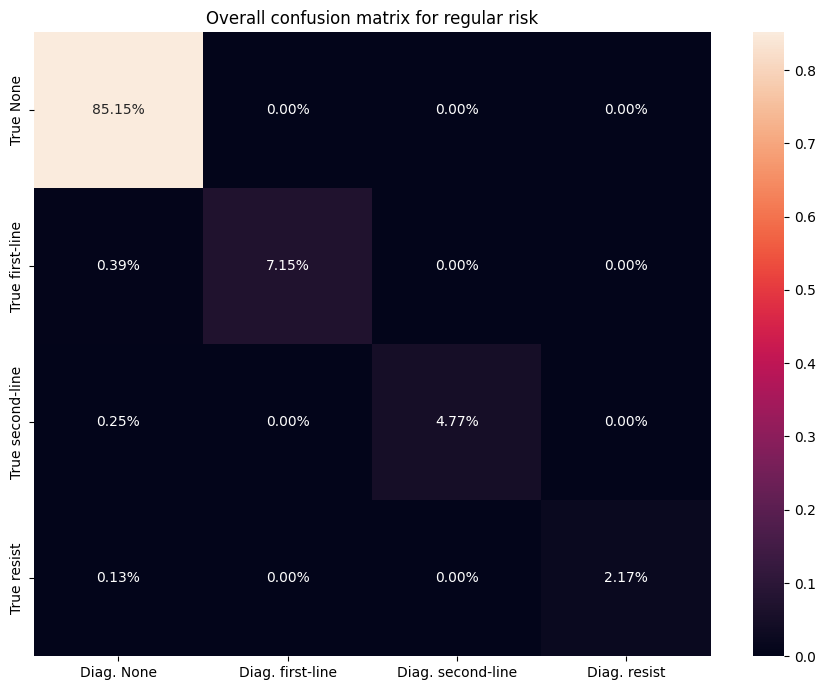

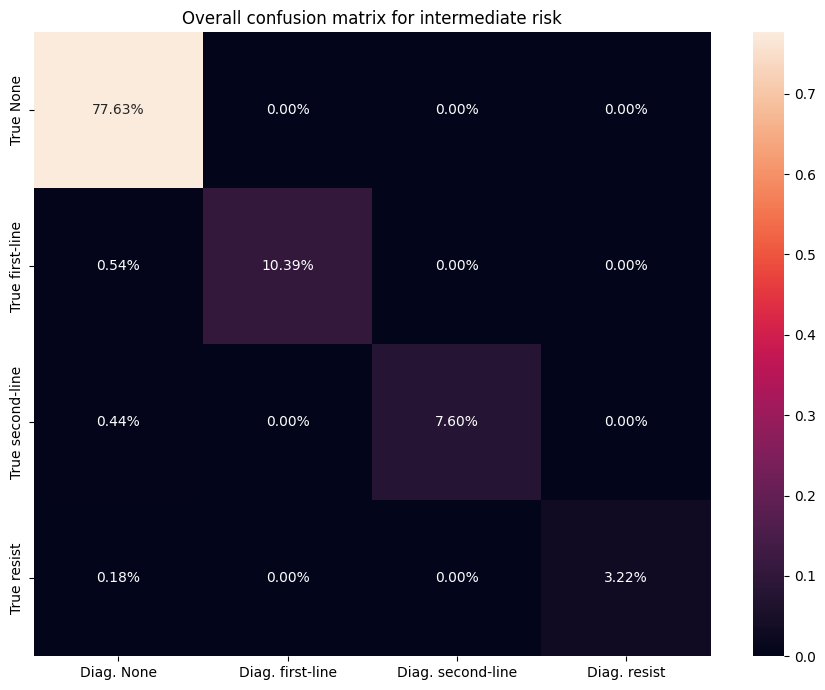

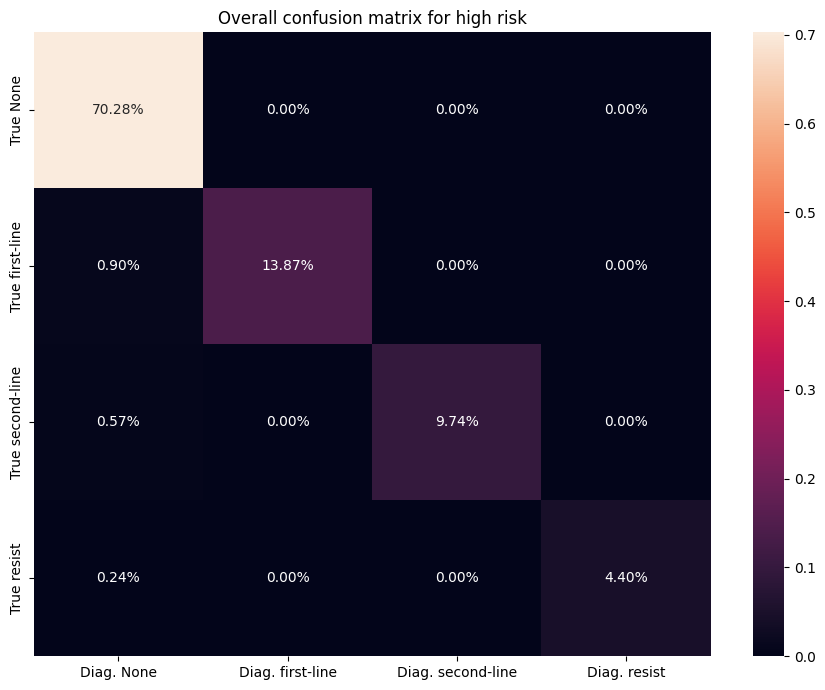

In [290]:
for i, matrix in enumerate(overall_confusion_matrices):
    normalized = matrix / matrix.sum()

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        normalized,
        yticklabels=["True None", "True first-line", "True second-line", "True resist"],
        xticklabels=["Diag. None", "Diag. first-line", "Diag. second-line", "Diag. resist"],
        annot=True,
        fmt=".2%",
    )
    plt.title(f"Overall confusion matrix for {risk_names[i]} risk")
    plt.tight_layout()
    plt.show()

In [291]:
# define the costs of each treatment strategy
qaly_lambda = 5
treatment_delays = {"clinical": 0, "dipstick": 0.1, "urine_culture": 2, "rapid_test": 0.1, "rapid_plus_ast": 3}
diagnostic_costs = {"clinical": 0, "dipstick": 5, "urine_culture": 8, "rapid_test": 15, "rapid_plus_ast": 35}
total_diagnostic_costs = {x: treatment_delays[x]*qaly_lambda + diagnostic_costs[x] for x in treatment_delays.keys()}
print(total_diagnostic_costs)

{'clinical': 0, 'dipstick': 5.5, 'urine_culture': 18, 'rapid_test': 15.5, 'rapid_plus_ast': 50}


In [292]:
# define the costs of successfully treating each strain
strain_treatments = np.array([0, 5, 10, 50])
def strain_to_idx(uti_strain):
    if uti_strain is None:
        return 0
    else:
        return uti_strain+1

In [293]:
# create cost matrix from confusion matrix, only accounts for actual treatments and diagnostic strategy
cost_matrix = np.zeros((1+len(true_strain_probs),1+len(true_strain_probs)))
resolution_delay = 5
extra_diag = 20
for i in range(0, 1+len(true_strain_probs)):
    for j in range(0, 1+len(true_strain_probs)):
        if i==j:
            cost_matrix[i,i] += strain_treatments[i]
        else:
            cost_matrix[i,j] += (strain_treatments[i] + strain_treatments[j] + qaly_lambda*resolution_delay + extra_diag)

print(cost_matrix)

[[  0.  50.  55.  95.]
 [ 50.   5.  60. 100.]
 [ 55.  60.  10. 105.]
 [ 95. 100. 105.  50.]]


In [294]:
# define benefits of treating each state
treatment_benefits = np.array([1,3,3.5,5])
benefit_mat = np.transpose(np.tile(treatment_benefits,(4,1)))
print(benefit_mat)

[[1.  1.  1.  1. ]
 [3.  3.  3.  3. ]
 [3.5 3.5 3.5 3.5]
 [5.  5.  5.  5. ]]


In [295]:
# net benefit matrix
net_ben_mat = (benefit_mat - cost_matrix)*overall_confusion_matrix - total_diagnostic_costs[chosen_strategy]
print(net_ben_mat)

[[-49.44685435 -57.54145432 -53.67022317 -53.38202961]
 [-52.39821954 -50.03599602 -50.51282946 -50.29100019]
 [-52.7809475  -50.9599361  -50.05848054 -50.30419601]
 [-51.43982014 -50.19019033 -50.59970045 -50.04499998]]
